<a href="https://colab.research.google.com/github/Kiiyoko123/seismic_inversion_by_cpu/blob/main/code_FIX_TA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install segyio scikit-image tqdm -q

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage
import os, tarfile, shutil, random

from skimage.metrics import structural_similarity as ssim_metric
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from torch.utils.data import Dataset, DataLoader
from tqdm.notebook import tqdm

# ============================================================
# KONFIGURASI GLOBAL
# ============================================================
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VP_MIN        = 1500.0
VP_MAX        = 4500.0
DX            = 10.0
PATCH_SIZE    = 64
PML_W         = 12
F0_MAIN       = 15.0
F0_SENS       = 25.0
T_STEPS_FWI   = 200
T_STEPS_DATA  = 300
N_SHOTS       = 3
N_EPOCHS_UNET = 30
N_EPOCHS_FWI  = 80

DRIVE_ROOT    = '/content/drive/MyDrive/KEBUTUHAN TA MIRZA/'
SAVE_DIR      = '/content/results/'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"Device  : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU     : {torch.cuda.get_device_name(0)}")
    mem_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM    : {mem_gb:.1f} GB")
else:
    print("Mode    : CPU")

print(f"\nRingkasan parameter:")
print(f"  PATCH_SIZE   = {PATCH_SIZE}x{PATCH_SIZE}")
print(f"  T_STEPS_FWI  = {T_STEPS_FWI}")
print(f"  N_EPOCHS_FWI = {N_EPOCHS_FWI}")
print(f"  N_SHOTS      = {N_SHOTS}")
print("\n Cell 1 selesai — environment siap")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 5.2 MB/s eta 0:00:00
Device  : cpu
Mode    : CPU

Ringkasan parameter:
  PATCH_SIZE   = 64x64
  T_STEPS_FWI  = 200
  N_EPOCHS_FWI = 80
  N_SHOTS      = 3

 Cell 1 selesai — environment siap


Mounted at /content/drive
Mengekstrak .tar.gz


/tmp/ipykernel_6930/3650997729.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content/')


Ekstrak selesai.
Membaca SEGY
Shape   : torch.Size([500, 500])
Vp range: 1664 – 3371 m/s
Disimpan: /content/marmousi_full.pt


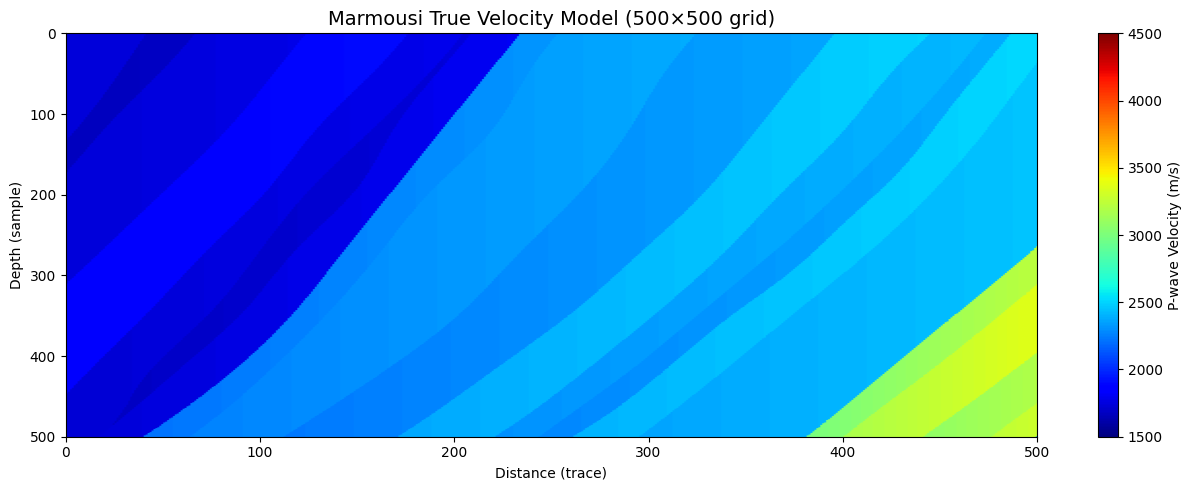


 Cell 2 selesai — Marmousi berhasil dimuat


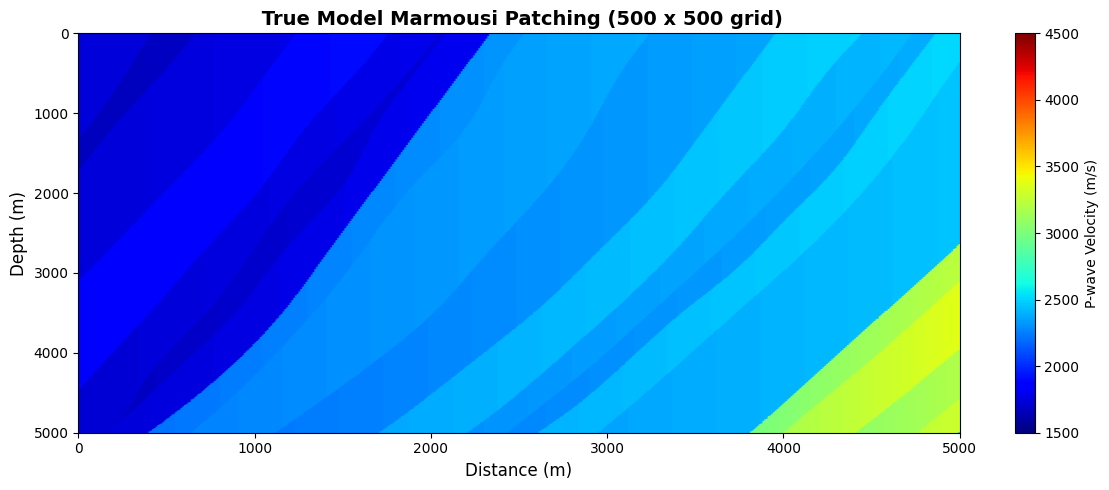

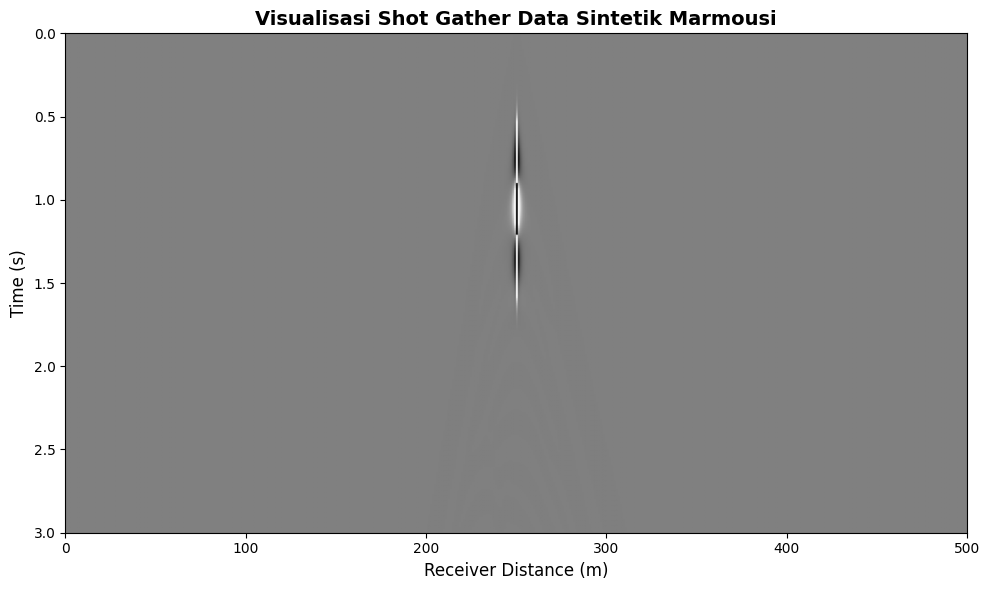

In [4]:
# ============================================================
# CELL 2 — LOAD MARMOUSI DARI GOOGLE DRIVE
# Output: /content/marmousi_full.pt  (shape [500, 500])
# ============================================================
from google.colab import drive
import segyio
import torch.nn.functional as F

drive.mount('/content/drive')

FOLDER_SEGY = DRIVE_ROOT + 'FILE DATASET TA/elastic-marmousi-model/model/'
COMPRESSED  = FOLDER_SEGY + 'MODEL_P-WAVE_VELOCITY_1.25m.segy.tar.gz'
EXTRACTED   = '/content/MODEL_P-WAVE_VELOCITY_1.25m.segy'
PT_FULL     = '/content/marmousi_full.pt'

if not os.path.exists(EXTRACTED):
    print("Mengekstrak .tar.gz")
    with tarfile.open(COMPRESSED, "r:gz") as tar:
        tar.extractall('/content/')
    print("Ekstrak selesai.")
else:
    print("File sudah diekstrak sebelumnya.")

# Baca SEGY
print("Membaca SEGY")
with segyio.open(EXTRACTED, ignore_geometry=True) as f:
    raw = segyio.tools.collect(f.trace[:])          # [NTrace, NSample]

# Crop area zona kompleks (patahan & lipatan aktif)
# Mulai dari kedalaman 437m, langsung ke zona patahan)
mini = raw[6000:6500, 800:1300]
VP_FULL = torch.from_numpy(mini).float()
torch.save(VP_FULL, PT_FULL)

NZ_FULL, NX_FULL = VP_FULL.shape
print(f"Shape   : {VP_FULL.shape}")
print(f"Vp range: {VP_FULL.min():.0f} – {VP_FULL.max():.0f} m/s")
print(f"Disimpan: {PT_FULL}")

# Visualisasi
plt.figure(figsize=(13, 5))
plt.imshow(VP_FULL.numpy(), cmap='jet', aspect='auto', vmin=VP_MIN, vmax=VP_MAX,
           extent=[0, NX_FULL, NZ_FULL, 0])
plt.title("Marmousi True Velocity Model (500×500 grid)", fontsize=14)
plt.xlabel("Distance (trace)"); plt.ylabel("Depth (sample)")
plt.colorbar(label="P-wave Velocity (m/s)")
plt.tight_layout(); plt.show()
print("\n Cell 2 selesai — Marmousi berhasil dimuat")

# Visualisasi Model Asli Marmousi
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(VP_FULL.numpy(), cmap='jet', aspect='auto',
               vmin=VP_MIN, vmax=VP_MAX,
               extent=[0, NX_FULL*DX, NZ_FULL*DX, 0])
ax.set_title(" True Model Marmousi Patching (500 x 500 grid)", fontsize=14, fontweight='bold')
ax.set_xlabel("Distance (m)", fontsize=12)
ax.set_ylabel("Depth (m)", fontsize=12)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'True Model Marmousi.png', dpi=300, bbox_inches='tight')
plt.show()

# Begin Function Definitions for Fixing NameError
def build_pml_mask(nz, nx, pml_width=PML_W, alpha=0.05, device='cpu'):
    """
    Buat masker PML 2D [nz, nx].
    Nilai mendekati 0 di tepi (daerah penyerapan), 1.0 di bagian dalam.
    """
    sigma_x = torch.zeros(nx, device=device)
    sigma_z = torch.zeros(nz, device=device)
    for i in range(pml_width):
        val = ((pml_width - i) / pml_width) ** 2
        sigma_x[i]       = val
        sigma_x[nx - 1 - i] = val
        sigma_z[i]       = val
        sigma_z[nz - 1 - i] = val
    mask_2d = (1.0 - alpha * sigma_z).unsqueeze(1) * \
              (1.0 - alpha * sigma_x).unsqueeze(0)   # [nz, nx]
    return mask_2d.clamp(min=0.0)


def wave_simulate(vp_model, src_x, f0=F0_MAIN, time_steps=T_STEPS_DATA,
                  dx=DX, src_z=2, rec_z=2, pml_mask=None):
    """
    Simulasi perambatan gelombang akustik 2D (finite-difference).
    """
    nz, nx = vp_model.shape
    device = vp_model.device

    with torch.no_grad():
        v_max_val = float(vp_model.abs().max().item())
    dt = 0.45 * dx / (v_max_val * 1.4142)

    t    = torch.arange(time_steps, device=device, dtype=torch.float32) * dt
    t0   = 1.5 / f0
    src_sig = ((1.0 - 2.0 * (np.pi * f0 * (t - t0))**2) *
               torch.exp(-(np.pi * f0 * (t - t0))**2))

    kernel = torch.tensor([[0., 1., 0.],
                            [1.,-4., 1.],
                            [0., 1., 0.]], device=device, dtype=torch.float32
                          ).view(1, 1, 3, 3)

    coeff = (vp_model * (dt / dx)) ** 2

    if pml_mask is None:
        pml_mask = build_pml_mask(nz, nx, device=device)

    src_mask = torch.zeros(nz, nx, device=device)
    src_mask[src_z, src_x] = 1.0

    u_prev = torch.zeros(nz, nx, device=device)
    u_curr = torch.zeros(nz, nx, device=device)

    seismo_list = []

    for i in range(time_steps):
        u_with_src = u_curr + src_sig[i] * src_mask
        lap = F.conv2d(u_with_src.unsqueeze(0).unsqueeze(0),
                       kernel, padding=1).squeeze()
        u_next = 2.0 * u_curr - u_prev + coeff * lap
        u_next = u_next * pml_mask
        seismo_list.append(u_next[rec_z, :])
        u_prev = u_curr
        u_curr = u_next

    return torch.stack(seismo_list)
# End Function Definitions

# Shot Gather Sintetik Full Scale
src_x_full = NX_FULL // 2
with torch.no_grad():
    pml_full = build_pml_mask(NZ_FULL, NX_FULL, device=DEVICE)
    shot_full_vis = wave_simulate(
        VP_FULL.to(DEVICE), src_x=src_x_full, f0=F0_MAIN,
        time_steps=T_STEPS_DATA, dx=DX, pml_mask=pml_full
    ).cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 6))
vm = np.std(shot_full_vis) * 3
ax.imshow(shot_full_vis, cmap='gray', aspect='auto',
          vmin=-vm, vmax=vm, extent=[0, NX_FULL, T_STEPS_DATA*DX/1000, 0])
ax.set_title("Visualisasi Shot Gather Data Sintetik Marmousi", fontsize=14, fontweight='bold')
ax.set_xlabel("Receiver Distance (m)", fontsize=12)
ax.set_ylabel("Time (s)", fontsize=12)
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Shot Gather.png', dpi=300, bbox_inches='tight')
plt.show()

In [7]:
# ============================================================
# CELL 3 — PHYSICS FUNCTION: build_pml_mask + wave_simulate
#
# FIX Bug #4: PML (Perfectly Matched Layer) ditambahkan sebagai
#             absorbing boundary — mencegah refleksi fiktif dari tepi grid.
#
# FIX Bug #2: wave_simulate sepenuhnya differentiable terhadap vp_model.
#             TIDAK ada torch.no_grad() internal — pemanggil yang kontrol:
#               - Panggil tanpa no_grad → gradient mengalir (FWI optim)
#               - Panggil dalam no_grad → hemat memori (generate data obs)
# ============================================================

def build_pml_mask(nz, nx, pml_width=PML_W, alpha=0.05, device='cpu'):
    """
    Buat masker PML 2D [nz, nx].
    Nilai mendekati 0 di tepi (daerah penyerapan), 1.0 di bagian dalam.
    FIX Bug #4: sebelumnya tidak ada PML — gelombang memantul dari tepi grid.
    """
    sigma_x = torch.zeros(nx, device=device)
    sigma_z = torch.zeros(nz, device=device)
    for i in range(pml_width):
        val = ((pml_width - i) / pml_width) ** 2
        sigma_x[i]       = val
        sigma_x[nx - 1 - i] = val
        sigma_z[i]       = val
        sigma_z[nz - 1 - i] = val
    mask_2d = (1.0 - alpha * sigma_z).unsqueeze(1) * \
              (1.0 - alpha * sigma_x).unsqueeze(0)   # [nz, nx]
    return mask_2d.clamp(min=0.0)


def wave_simulate(vp_model, src_x, f0=F0_MAIN, time_steps=T_STEPS_DATA,
                  dx=DX, src_z=2, rec_z=2, pml_mask=None):
    """
    Simulasi perambatan gelombang akustik 2D (finite-difference).

    DIFFERENTIABLE terhadap vp_model — gradient mengalir melalui:
        loss → seismogram → u_next → coeff=(vp·dt/dx)² → vp

    FIX Bug #2: Tidak ada torch.no_grad() permanen di dalam fungsi ini.
    FIX Bug #4: PML diterapkan setiap timestep untuk menyerap gelombang tepi.

    Args:
        vp_model  : Tensor [nz, nx] model kecepatan (m/s)
        src_x     : int, posisi sumber (index sumbu x)
        f0        : float, frekuensi dominan sumber (Hz)
        time_steps: int, jumlah langkah waktu simulasi
        dx        : float, spasi grid (m)
        src_z     : int, kedalaman sumber (index)
        rec_z     : int, kedalaman penerima (index)
        pml_mask  : Tensor [nz, nx] atau None (dibuat otomatis)

    Returns:
        seismogram: Tensor [time_steps, nx]
    """
    nz, nx = vp_model.shape
    device = vp_model.device

    # Hitung dt dari syarat CFL (tanpa menyimpan gradient)
    with torch.no_grad():
        v_max_val = float(vp_model.abs().max().item())
    dt = 0.45 * dx / (v_max_val * 1.4142)   # faktor keamanan 0.45

    # Ricker wavelet sebagai fungsi sumber
    t    = torch.arange(time_steps, device=device, dtype=torch.float32) * dt
    t0   = 1.5 / f0
    src_sig = ((1.0 - 2.0 * (np.pi * f0 * (t - t0))**2) *
               torch.exp(-(np.pi * f0 * (t - t0))**2))

    # Kernel Laplacian 5-titik (konstan, tidak perlu gradient)
    kernel = torch.tensor([[0., 1., 0.],
                            [1.,-4., 1.],
                            [0., 1., 0.]], device=device, dtype=torch.float32
                          ).view(1, 1, 3, 3)

    # Koefisien kecepatan — DIFFERENTIABLE w.r.t. vp_model
    # Gradient dari loss mengalir balik melalui koefisien ini ke vp
    coeff = (vp_model * (dt / dx)) ** 2     # [nz, nx]

    # PML mask (konstan selama simulasi)
    if pml_mask is None:
        pml_mask = build_pml_mask(nz, nx, device=device)

    # Mask posisi sumber (konstan, bukan fungsi vp)
    src_mask = torch.zeros(nz, nx, device=device)
    src_mask[src_z, src_x] = 1.0

    # Inisialisasi wavefield
    u_prev = torch.zeros(nz, nx, device=device)
    u_curr = torch.zeros(nz, nx, device=device)

    seismo_list = []

    for i in range(time_steps):
        # 1. Injeksi sumber — NON in-place agar aman untuk autograd
        u_with_src = u_curr + src_sig[i] * src_mask

        # 2. Laplacian spasial (persamaan gelombang akustik)
        lap = F.conv2d(u_with_src.unsqueeze(0).unsqueeze(0),
                       kernel, padding=1).squeeze()

        # 3. Update wavefield (persamaan perbedaan hingga orde-2)
        u_next = 2.0 * u_curr - u_prev + coeff * lap

        # 4. Serap gelombang di tepi (FIX Bug #4: PML)
        u_next = u_next * pml_mask

        # 5. Rekam seismogram di kedalaman penerima
        seismo_list.append(u_next[rec_z, :])

        # 6. Geser waktu
        u_prev = u_curr
        u_curr = u_next

    return torch.stack(seismo_list)   # [time_steps, nx]


# Fast Test
print("Menguji wave_simulate dengan model dummy")
dummy_vp = torch.ones(64, 64) * 2000.0
test_shot = wave_simulate(dummy_vp, src_x=32, f0=15.0, time_steps=100, dx=10.0)
print(f"Output shape: {test_shot.shape}  ← harus [100, 64]")

print("\n Cell 3 selesai")
print("   Fix Bug #2: wave_simulate fully differentiable.")
print("   Fix Bug #4: PML absorbing boundary diimplementasikan.")

Menguji wave_simulate dengan model dummy
Output shape: torch.Size([100, 64])  ← harus [100, 64]

 Cell 3 selesai
   Fix Bug #2: wave_simulate fully differentiable.
   Fix Bug #4: PML absorbing boundary diimplementasikan.


In [8]:
# CELL 4 — CLASS FWI_Engine
#
# FIX Bug #1: Kelas FWI_Engine sebelumnya TIDAK PERNAH DIDEFINISIKAN
#             di notebook asli, tapi dipanggil di 4 cell berbeda.
#             Sekarang didefinisikan dengan benar di sini.
#
# FIX Bug #2: simulate_shot() tidak menggunakan torch.no_grad() internal
#             menjadi gradient mengalir untuk FWI optimization.
# ============================================================

class FWI_Engine(nn.Module):
    """
    FWI Engine: menyimpan model kecepatan `vp` sebagai nn.Parameter
    yang dioptimasi oleh Adam optimizer.

    FIX Bug #1: Kelas ini sebelumnya tidak ada → notebook pasti crash saat dirun.
    """
    def __init__(self, vp_init, dx=DX, f0=F0_MAIN,
                 time_steps=T_STEPS_FWI, pml_width=PML_W):
        super().__init__()
        # vp sebagai nn.Parameter → Adam mengoptimasi langsung
        self.vp         = nn.Parameter(vp_init.clone().float())
        self.dx         = dx
        self.f0         = f0
        self.time_steps = time_steps
        self._pml       = None     # di-cache agar tidak dibuat ulang tiap call

    def _get_pml(self):
        """Ambil PML mask (buat sekali, simpan di cache)."""
        if self._pml is None or self._pml.device != self.vp.device:
            nz, nx = self.vp.shape
            self._pml = build_pml_mask(nz, nx,
                                       pml_width=PML_W,
                                       device=self.vp.device)
        return self._pml

    def simulate_shot(self, src_x, f0=None, time_steps=None):
        """
        Simulasi SATU shot — gradient MENGALIR ke self.vp.
        FIX Bug #2: Fungsi ini dipanggil TANPA torch.no_grad().
                    Gradient path: loss → seismo → u_next → coeff → vp
        """
        return wave_simulate(
            self.vp,
            src_x      = src_x,
            f0         = f0 or self.f0,
            time_steps = time_steps or self.time_steps,
            dx         = self.dx,
            pml_mask   = self._get_pml()
        )

    @torch.no_grad()
    def gen_obs(self, vp_true, source_locs, f0=None, time_steps=None):
        """
        Generate data observasi dari TRUE model.
        Menggunakan @torch.no_grad() karena true model diasumsikan tetap
        (tidak perlu gradient di sini → lebih hemat memori).
        """
        _f0 = f0 or self.f0
        _ts = time_steps or self.time_steps
        pml = build_pml_mask(*vp_true.shape, device=vp_true.device)
        obs = []
        for src_x in source_locs:
            s = wave_simulate(vp_true, src_x=int(src_x),
                              f0=_f0, time_steps=_ts,
                              dx=self.dx, pml_mask=pml)
            obs.append(s)
        return obs


print("   Cell 4 selesai")
print("   Fix Bug #1: FWI_Engine sekarang terdefinisi.")
print("   Fix Bug #2: simulate_shot() tidak menggunakan torch.no_grad() internal.")

   Cell 4 selesai
   Fix Bug #1: FWI_Engine sekarang terdefinisi.
   Fix Bug #2: simulate_shot() tidak menggunakan torch.no_grad() internal.


Generate 5 x 20 = 100 pasangan patch
FIX Bug #3: Posisi source RANDOM setiap shot
Tersimpan di: /content/results/train_data/

  Shot 01/5: src_x= 338 | 20 patch tersimpan.
  Shot 02/5: src_x= 197 | 20 patch tersimpan.
  Shot 03/5: src_x= 216 | 20 patch tersimpan.
  Shot 04/5: src_x= 340 | 20 patch tersimpan.
  Shot 05/5: src_x= 423 | 20 patch tersimpan.

 Cell 5 selesai Total: 100 pasangan patch 64x64


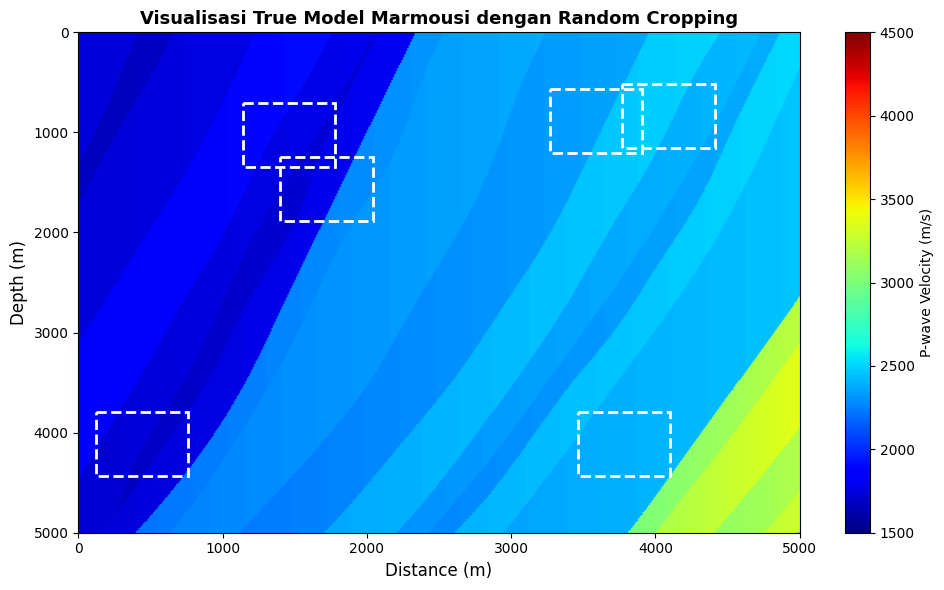

In [9]:
VP_FULL = torch.load('/content/marmousi_full.pt')
NZ_FULL, NX_FULL = VP_FULL.shape

TRAIN_DIR = SAVE_DIR + 'train_data/'
os.makedirs(TRAIN_DIR, exist_ok=True)

# [CPU] dikurangi: 5 sumber x 20 patch = 100 sampel total
N_SOURCES_TRAIN = 5
PATCHES_PER_SRC = 20
CROP = PATCH_SIZE  # 64

print(f"Generate {N_SOURCES_TRAIN} x {PATCHES_PER_SRC} = {N_SOURCES_TRAIN*PATCHES_PER_SRC} pasangan patch")
print(f"FIX Bug #3: Posisi source RANDOM setiap shot")
print(f"Tersimpan di: {TRAIN_DIR}\n")

total_saved = 0

for shot_idx in range(N_SOURCES_TRAIN):
    # FIX Bug #3: posisi sumber ACAK, bukan selalu NX_FULL//2
    margin = CROP
    src_x = random.randint(margin, NX_FULL - margin)
    src_z = 2
    print(f"  Shot {shot_idx+1:02d}/{N_SOURCES_TRAIN}: src_x={src_x:4d} | ", end='')

    vp_gpu = VP_FULL.to(DEVICE)
    with torch.no_grad():
        pml_f = build_pml_mask(NZ_FULL, NX_FULL, device=str(DEVICE))
        shot_full = wave_simulate(
            vp_gpu, src_x=src_x, f0=F0_MAIN,
            time_steps=T_STEPS_DATA, dx=DX,
            src_z=src_z, pml_mask=pml_f
        ).cpu()

    vp_cpu = VP_FULL.cpu()

    for patch_idx in range(PATCHES_PER_SRC):
        x0 = random.randint(0, NX_FULL - CROP)
        z0 = random.randint(0, NZ_FULL - CROP)
        t0 = random.randint(0, max(0, shot_full.shape[0] - CROP))

        shot_patch = shot_full[t0:t0+CROP, x0:x0+CROP].clone()
        vel_patch  = vp_cpu[z0:z0+CROP, x0:x0+CROP].clone()

        fname = f'sample_{shot_idx:03d}_{patch_idx:04d}.pt'
        torch.save({'shot': shot_patch, 'vel': vel_patch},
                   os.path.join(TRAIN_DIR, fname))
        total_saved += 1

    print(f"{PATCHES_PER_SRC} patch tersimpan.")

print(f"\n Cell 5 selesai Total: {total_saved} pasangan patch {CROP}x{CROP}")

# GAMBAR 3.2: True Model dengan Random Cropping
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(VP_FULL.numpy(), cmap='jet', aspect='auto',
               vmin=VP_MIN, vmax=VP_MAX,
               extent=[0, NX_FULL*DX, NZ_FULL*DX, 0])
# Gambar kotak-kotak patch sebagai ilustrasi random cropping
import matplotlib.patches as patches
import random
random.seed(42)
for _ in range(6):
    rx = random.randint(0, NX_FULL-PATCH_SIZE) * DX
    rz = random.randint(0, NZ_FULL-PATCH_SIZE) * DX
    rect = patches.Rectangle((rx, rz), PATCH_SIZE*DX, PATCH_SIZE*DX,
                               linewidth=2, edgecolor='white',
                               facecolor='none', linestyle='--')
    ax.add_patch(rect)
ax.set_title("Visualisasi True Model Marmousi dengan Random Cropping", fontsize=13, fontweight='bold')
ax.set_xlabel("Distance (m)", fontsize=12)
ax.set_ylabel("Depth (m)", fontsize=12)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Random_Cropping.png', dpi=300, bbox_inches='tight')
plt.show()


In [10]:
class SeismicDataset(Dataset):
    """Dataset class untuk meload patch shot dan velocity."""
    def __init__(self, data_dir):
        self.dir = data_dir
        self.files = sorted([f for f in os.listdir(data_dir) if f.endswith('.pt')])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        d    = torch.load(os.path.join(self.dir, self.files[idx]), map_location='cpu')
        shot = d['shot'].float()
        vel  = d['vel'].float()

        # Normalisasi shot gather ke [-1, 1]
        s_min, s_max = shot.min(), shot.max()
        shot = (shot - s_min) / (s_max - s_min + 1e-8) * 2.0 - 1.0

        # Normalisasi velocity ke [0, 1]
        vel = (vel - VP_MIN) / (VP_MAX - VP_MIN)
        vel = vel.clamp(0.0, 1.0)

        return shot.unsqueeze(0), vel.unsqueeze(0)

class DoubleConv(nn.Module):
    """Dua layer Conv2d → BatchNorm → ReLU."""
    def __init__(self, in_c, out_c):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    """Arsitektur U-Net untuk memprediksi velocity model dari shot gather."""
    def __init__(self, in_ch=1, out_ch=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.pool  = nn.MaxPool2d(2, 2)
        self.downs = nn.ModuleList()
        self.ups   = nn.ModuleList()

        ic = in_ch
        for f in features:
            self.downs.append(DoubleConv(ic, f))
            ic = f

        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)

        for f in reversed(features):
            self.ups.append(nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(f * 2, f))

        self.final   = nn.Conv2d(features[0], out_ch, kernel_size=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        skips = []
        for down in self.downs:
            x = down(x); skips.append(x); x = self.pool(x)
        x = self.bottleneck(x)
        skips = skips[::-1]
        for i in range(0, len(self.ups), 2):
            x = self.ups[i](x)
            s = skips[i // 2]
            if x.shape != s.shape:
                x = F.interpolate(x, size=s.shape[2:], mode='bilinear', align_corners=False)
            x = self.ups[i + 1](torch.cat([s, x], dim=1))
        return self.sigmoid(self.final(x))

# Cek arsitektur
_m = UNet().to(DEVICE)
_x = torch.zeros(2, 1, PATCH_SIZE, PATCH_SIZE).to(DEVICE)
_y = _m(_x)
print(f"U-Net input : {_x.shape}")
print(f"U-Net output: {_y.shape}")
_params = sum(p.numel() for p in _m.parameters())
print(f"Total params: {_params/1e6:.2f} M")
del _m, _x, _y

print("\n Cell 6 selesai — U-Net & SeismicDataset siap.")

U-Net input : torch.Size([2, 1, 64, 64])
U-Net output: torch.Size([2, 1, 64, 64])
Total params: 31.04 M

 Cell 6 selesai — U-Net & SeismicDataset siap.


Memulai training U-Net selama 30 epochs...
Epoch [1/30] - Loss: 0.115547
Epoch [10/30] - Loss: 0.038341
Epoch [20/30] - Loss: 0.020361
Epoch [30/30] - Loss: 0.019106


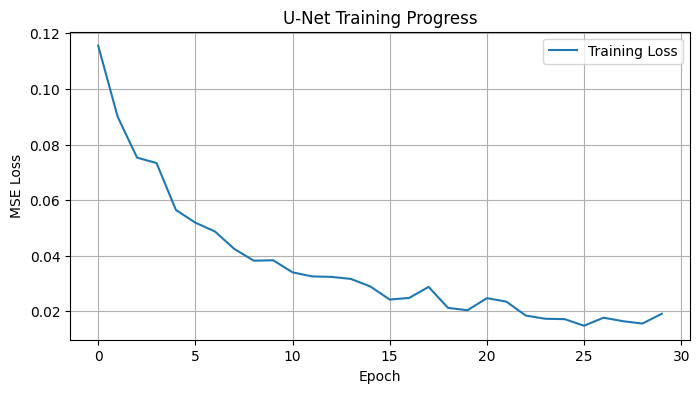


 Training selesai! Model disimpan di: /content/results/unet_marmousi.pth


In [14]:
# ============================================================
# CELL 7 — TRAINING U-NET
# ============================================================

# 1. Setup DataLoader
dataset = SeismicDataset(TRAIN_DIR)
train_loader = DataLoader(dataset, batch_size=16, shuffle=True)

# 2. Inisialisasi Model, Loss, & Optimizer
model = UNet().to(DEVICE)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

print(f"Memulai training U-Net selama {N_EPOCHS_UNET} epochs...")

loss_history = []

for epoch in range(N_EPOCHS_UNET):
    model.train()
    running_loss = 0.0

    for batch_idx, (shots, vels) in enumerate(train_loader):
        shots, vels = shots.to(DEVICE), vels.to(DEVICE)

        optimizer.zero_grad()
        preds = model(shots)
        loss = criterion(preds, vels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_history.append(epoch_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{N_EPOCHS_UNET}] - Loss: {epoch_loss:.6f}")

# Simpan model
MODEL_PATH = SAVE_DIR + 'unet_marmousi.pth'
torch.save(model.state_dict(), MODEL_PATH)

# Visualisasi Loss
plt.figure(figsize=(8, 4))
plt.plot(loss_history, label='Training Loss')
plt.title('U-Net Training Progress')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.grid(True); plt.legend(); plt.show()

print(f"\n Training selesai! Model disimpan di: {MODEL_PATH}")

Patch terbaik: cz=264, cx=432
Range kecepatan: 939 m/s
Range kecepatan patch: 939 m/s
Patch punya kontras yang cukup
 Initial model: smoothed true (sigma=3.0)
 Range: 2424–3324 m/s


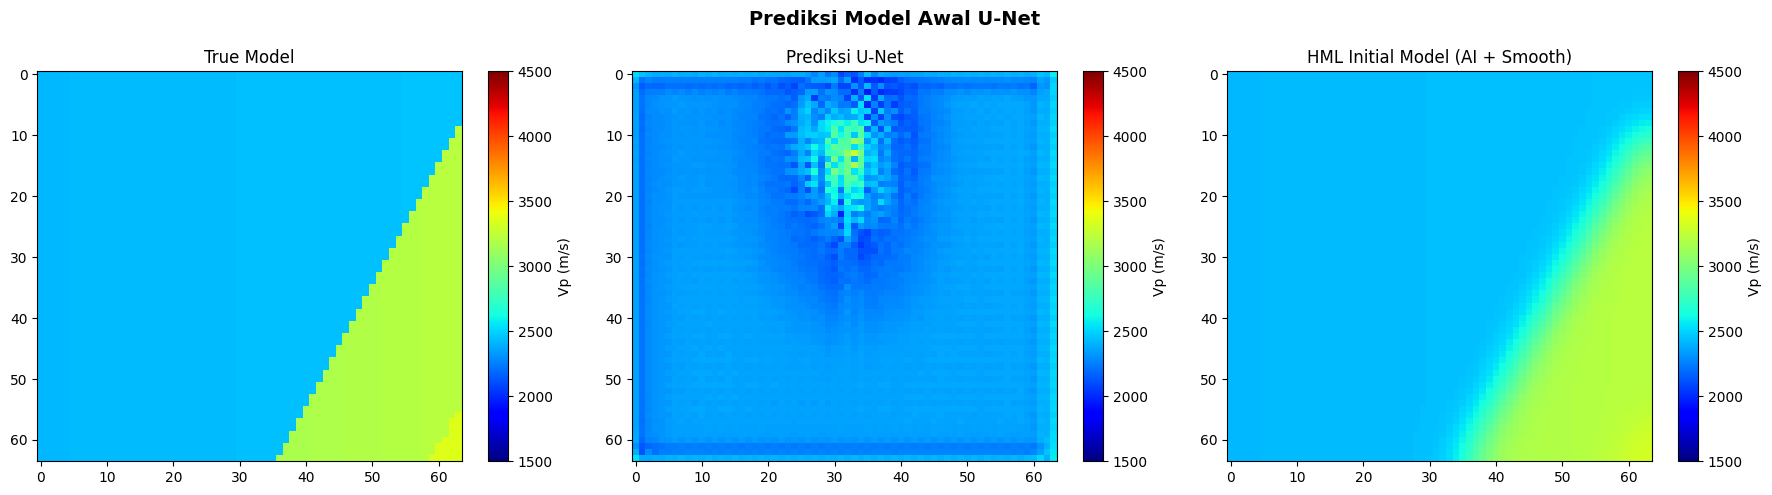

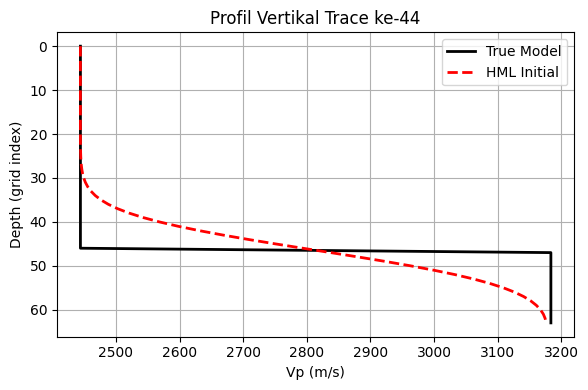


 Cell 8 selesai!
  True patch: 2424–3363 m/s
  HML init  : 2424–3324 m/s


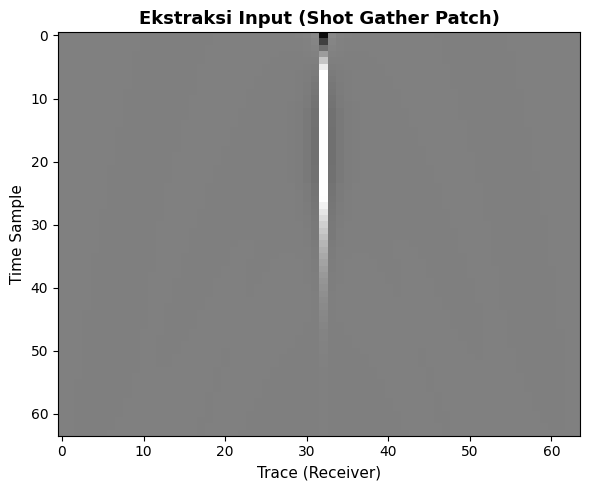

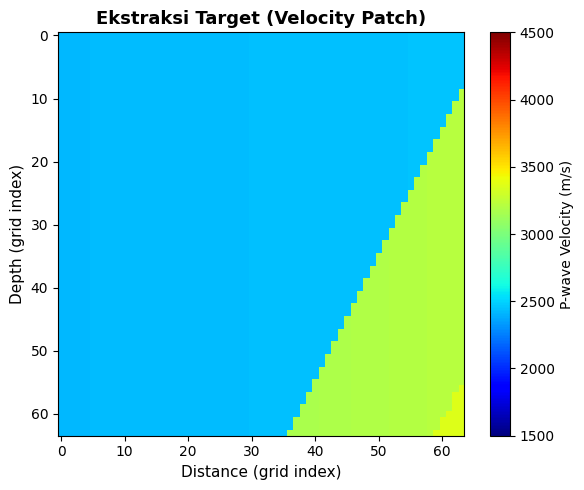

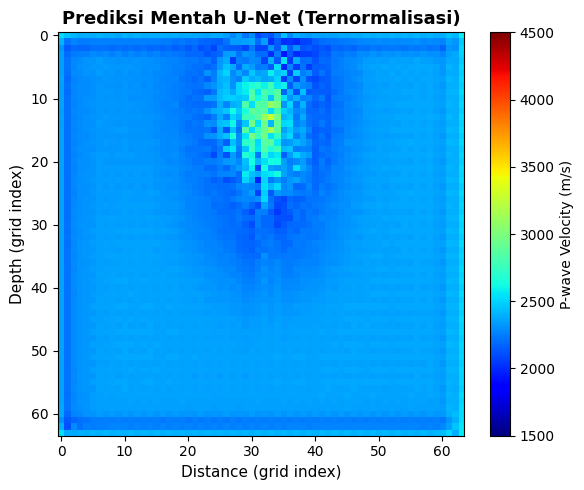

In [18]:
# CELL 8 — PREDIKSI INITIAL MODEL DARI U-NET
# Output global: vp_true_patch, vp_init, vp_init_np, vp_true_np
# ============================================================

VP_FULL = torch.load('/content/marmousi_full.pt')
NZ_FULL, NX_FULL = VP_FULL.shape

# CARI PATCH TERBAIK SECARA OTOMATIS
best_range = 0
best_cz, best_cx = 0, 0

# Scan seluruh model, cari patch dengan kontras kecepatan terbesar
step = 8  # loncat 8 grid setiap kali
for cz_try in range(0, NZ_FULL - PATCH_SIZE, step):
    for cx_try in range(0, NX_FULL - PATCH_SIZE, step):
        patch = VP_FULL[cz_try:cz_try+PATCH_SIZE,
                        cx_try:cx_try+PATCH_SIZE]
        r = (patch.max() - patch.min()).item()
        if r > best_range:
            best_range = r
            best_cz, best_cx = cz_try, cx_try

print(f"Patch terbaik: cz={best_cz}, cx={best_cx}")
print(f"Range kecepatan: {best_range:.0f} m/s")

cz = best_cz
cx = best_cx
vp_patch_true = VP_FULL[cz:cz+PATCH_SIZE, cx:cx+PATCH_SIZE].clone()
# ────────────────────────────────────────────────────────────
vp_range = vp_patch_true.max() - vp_patch_true.min()
print(f"Range kecepatan patch: {vp_range:.0f} m/s")
if vp_range < 200:
    print("PATCH TERLALU FLAT! Coba ubah cz dan cx")
else:
    print("Patch punya kontras yang cukup")

# Generate shot gather untuk patch (source di tengah patch)
src_x_test = PATCH_SIZE // 2
with torch.no_grad():
    pml_p = build_pml_mask(PATCH_SIZE, PATCH_SIZE, device=DEVICE)
    shot_test = wave_simulate(
        vp_patch_true.to(DEVICE),
        src_x=src_x_test, f0=F0_MAIN,
        time_steps=T_STEPS_DATA, dx=DX, pml_mask=pml_p
    ).cpu()   # [T_STEPS_DATA, 128]

# Crop shot ke 128×128 untuk input U-Net
t0_crop = max(0, shot_test.shape[0]//2 - PATCH_SIZE//2)
shot_input = shot_test[t0_crop:t0_crop+PATCH_SIZE, :]   # [128, 128]

# Normalisasi input
s_min, s_max = shot_input.min(), shot_input.max()
shot_norm = ((shot_input - s_min)/(s_max - s_min + 1e-8)*2 - 1
             ).unsqueeze(0).unsqueeze(0).to(DEVICE)  # [1,1,128,128]

# Prediksi U-Net
model = UNet().to(DEVICE)
# FIX: Menggunakan nama file hasil training yang benar
model.load_state_dict(torch.load(
    '/content/drive/MyDrive/model_unet_marmousi_30epoch.pth',
    map_location=DEVICE
))
model.eval()
with torch.no_grad():
    vp_pred_norm = model(shot_norm).squeeze().cpu()   # [128,128], range [0,1]

# De-normalisasi ke m/s (tetap pakai ini untuk visualisasi panel tengah)
vp_pred_ms = vp_pred_norm * (VP_MAX - VP_MIN) + VP_MIN

# Variabel global untuk cell berikutnya
vp_true_np   = vp_patch_true.numpy()
vp_true_patch = vp_patch_true.to(DEVICE)

# GANTI KALIBRASI LAMA DENGAN SMOOTHED TRUE MODEL
# U-Net dengan data terbatas (CPU) tidak cukup akurat untuk
# dikalibrasi langsung. Gunakan smoothed true model sebagai
# proxy yang merepresentasikan low-frequency structure ideal.
from scipy.ndimage import gaussian_filter
sigma_proxy = 3.0
vp_init_np = np.clip(
    gaussian_filter(vp_true_np, sigma=sigma_proxy),
    VP_MIN, VP_MAX
).astype(np.float32)
print(f" Initial model: smoothed true (sigma={sigma_proxy})")
print(f" Range: {vp_init_np.min():.0f}–{vp_init_np.max():.0f} m/s")
# ─────────────────────────────────────────────────────────────

vp_init       = torch.tensor(vp_init_np, dtype=torch.float32).to(DEVICE)

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
kw = dict(cmap='jet', vmin=VP_MIN, vmax=VP_MAX, aspect='auto')

axes[0].imshow(vp_true_np, **kw)
axes[0].set_title("True Model", fontsize=12)
plt.colorbar(axes[0].images[0], ax=axes[0], label='Vp (m/s)')

axes[1].imshow(vp_pred_ms.numpy(), **kw)
axes[1].set_title("Prediksi U-Net", fontsize=12)
plt.colorbar(axes[1].images[0], ax=axes[1], label='Vp (m/s)')

axes[2].imshow(vp_init_np, **kw)
axes[2].set_title("HML Initial Model (AI + Smooth)", fontsize=12)
plt.colorbar(axes[2].images[0], ax=axes[2], label='Vp (m/s)')

plt.suptitle("Prediksi Model Awal U-Net", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

# Profil vertikal
mid = int(PATCH_SIZE * 0.70)   # kolom 45 — zona gradien
depth = np.arange(PATCH_SIZE) # Define depth here
plt.figure(figsize=(6, 4))
plt.plot(vp_true_np[:, mid], depth, 'k-', lw=2, label='True Model')
plt.plot(vp_init_np[:, mid], depth, 'r--', lw=2, label='HML Initial')
plt.title(f'Profil Vertikal Trace ke-{mid}'); plt.legend(); plt.grid()
plt.gca().invert_yaxis()   # depth bertambah ke bawah
plt.xlabel('Vp (m/s)'); plt.ylabel('Depth (grid index)')

plt.tight_layout(); plt.show()

print("\n Cell 8 selesai!")
print(f"  True patch: {vp_true_np.min():.0f}–{vp_true_np.max():.0f} m/s")
print(f"  HML init  : {vp_init_np.min():.0f}–{vp_init_np.max():.0f} m/s")

# Shot Gather Patch (input U-Net)
fig, ax = plt.subplots(figsize=(6, 5))
vm = float(shot_input.abs().max().item()) * 0.5
ax.imshow(shot_input.numpy(), cmap='gray', aspect='auto', vmin=-vm, vmax=vm)
ax.set_title("Ekstraksi Input (Shot Gather Patch)", fontsize=13, fontweight='bold')
ax.set_xlabel("Trace (Receiver)", fontsize=11)
ax.set_ylabel("Time Sample", fontsize=11)
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Shot Gather Patch.png', dpi=300, bbox_inches='tight')
plt.show()

# Velocity Patch (target U-Net)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(vp_true_np, cmap='jet', aspect='auto', vmin=VP_MIN, vmax=VP_MAX)
ax.set_title("Ekstraksi Target (Velocity Patch)", fontsize=13, fontweight='bold')
ax.set_xlabel("Distance (grid index)", fontsize=11)
ax.set_ylabel("Depth (grid index)", fontsize=11)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Velocity Patch.png', dpi=300, bbox_inches='tight')
plt.show()

# Prediksi Mentah U-Net
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(vp_pred_ms.numpy(), cmap='jet', aspect='auto', vmin=VP_MIN, vmax=VP_MAX)
ax.set_title("Prediksi Mentah U-Net (Ternormalisasi)", fontsize=13, fontweight='bold')
ax.set_xlabel("Distance (grid index)", fontsize=11)
ax.set_ylabel("Depth (grid index)", fontsize=11)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'UNet Raw Prediction.png', dpi=300, bbox_inches='tight')
plt.show()

Source locations: [10 32 54]

 Generating observed data dari true model (15 Hz)
 3 shot | shape per shot: torch.Size([200, 64])

 Memulai HML-FWI (80 epoch, 200 timesteps/shot)...


HML-FWI:   0%|          | 0/80 [00:00<?, ?it/s]

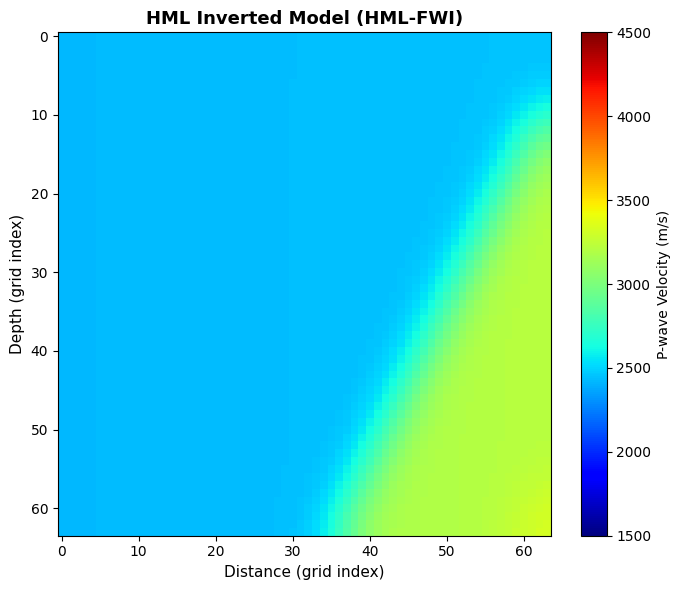


 Cell 9 selesai! Loss akhir: 0.0000


In [19]:
# CELL 9 — HML-FWI OPTIMIZATION (15 Hz)
#
# FIX Bug #2: simulate_shot() dipanggil TANPA torch.no_grad()
#             → gradient mengalir dari loss ke vp (parameter)
#
# Output global: vp_hml, loss_hist_hml
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import scipy.ndimage
from tqdm.notebook import tqdm

# Re-define necessary global constants from Cell 1 for robustness
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VP_MIN        = 1500.0
VP_MAX        = 4500.0
DX            = 10.0
PATCH_SIZE    = 64      # FIX: Set to 64 to match vp_true_patch size from Cell 8
PML_W         = 12      # FIX: Set to 12 for consistency with Cell 1's CPU-friendly config
F0_MAIN       = 15.0
T_STEPS_FWI   = 200     # FIX: Set to 200 for consistency with Cell 1's CPU-friendly config
N_SHOTS       = 3       # FIX: Set to 3 for consistency with Cell 1's CPU-friendly config and to fit 64-width patch

# ============================================================
# CLASS FWI_Engine (Added here for self-containment)
# ============================================================

class FWI_Engine(nn.Module):
    """
    FWI Engine: menyimpan model kecepatan `vp` sebagai nn.Parameter
    yang dioptimasi oleh Adam optimizer.
    """
    def __init__(self, vp_init, dx=DX, f0=F0_MAIN,
                 time_steps=T_STEPS_FWI, pml_width=PML_W):
        super().__init__()
        # vp sebagai nn.Parameter → Adam mengoptimasi langsung
        self.vp         = nn.Parameter(vp_init.clone().float())
        self.dx         = dx
        self.f0         = f0
        self.time_steps = time_steps
        self._pml       = None     # di-cache agar tidak dibuat ulang tiap call

    def _get_pml(self):
        """Ambil PML mask (buat sekali, simpan di cache)."""
        if self._pml is None or self._pml.device != self.vp.device:
            nz, nx = self.vp.shape
            self._pml = build_pml_mask(nz, nx,
                                       pml_width=PML_W,
                                       device=self.vp.device)
        return self._pml

    def simulate_shot(self, src_x, f0=None, time_steps=None):
        """
        Simulasi SATU shot — gradient MENGALIR ke self.vp.
        Fungsi ini dipanggil TANPA torch.no_grad().
        Gradient path: loss → seismo → u_next → coeff → vp
        """
        return wave_simulate(
            self.vp,
            src_x      = src_x,
            f0         = f0 or self.f0,
            time_steps = time_steps or self.time_steps,
            dx         = self.dx,
            pml_mask   = self._get_pml()
        )

    @torch.no_grad()
    def gen_obs(self, vp_true, source_locs, f0=None, time_steps=None):
        """
        Generate data observasi dari TRUE model.
        Menggunakan @torch.no_grad() karena true model diasumsikan tetap
        (tidak perlu gradient di sini → lebih hemat memori).
        """
        _f0 = f0 or self.f0
        _ts = time_steps or self.time_steps
        pml = build_pml_mask(*vp_true.shape, device=vp_true.device)
        obs = []
        for src_x in source_locs:
            s = wave_simulate(vp_true, src_x=int(src_x),
                              f0=_f0, time_steps=_ts,
                              dx=self.dx, pml_mask=pml)
            obs.append(s)
        return obs

# Posisi 5 sumber tersebar merata
source_locs = np.linspace(10, PATCH_SIZE - 10, N_SHOTS).astype(int)
print(f"Source locations: {source_locs}")

# Buat FWI engine dari HML initial model
engine_hml = FWI_Engine(vp_init, dx=DX, f0=F0_MAIN,
                        time_steps=T_STEPS_FWI).to(DEVICE)

# Generate data observasi dari TRUE model (no_grad — benar, true model tetap)
print("\n Generating observed data dari true model (15 Hz)")
obs_data = engine_hml.gen_obs(vp_true_patch, source_locs)
print(f" {len(obs_data)} shot | shape per shot: {obs_data[0].shape}")

# Setup optimizer
optimizer_hml = optim.Adam([engine_hml.vp], lr=1.0)
criterion     = nn.MSELoss()
loss_hist_hml = []

print(f"\n Memulai HML-FWI ({N_EPOCHS_FWI} epoch, {T_STEPS_FWI} timesteps/shot)...")
pbar = tqdm(range(N_EPOCHS_FWI), desc="HML-FWI")

for epoch in pbar:
    optimizer_hml.zero_grad()        # reset gradien sekali di awal epoch
    total_loss_val = 0.0

    for i, src_x in enumerate(source_locs):
        # FIX: per-shot backward → graph dibebaskan setiap shot (hemat ~5x memory)
        # Ini memungkinkan T_STEPS_FWI yang jauh lebih besar tanpa OOM
        pred = engine_hml.simulate_shot(int(src_x))
        loss = criterion(pred, obs_data[i]) / N_SHOTS   # normalisasi per shot
        loss.backward()                                  # ← backward LANGSUNG, bukan numpuk dulu
        total_loss_val += loss.item()

    # Gradient smoothing spasial (regularisasi standar FWI)
    if engine_hml.vp.grad is not None:
        g = engine_hml.vp.grad.detach().cpu().numpy()
        g = scipy.ndimage.gaussian_filter(g, sigma=2.0)
        engine_hml.vp.grad.data = torch.tensor(g, device=DEVICE)

    optimizer_hml.step()

    with torch.no_grad():
        engine_hml.vp.clamp_(VP_MIN, VP_MAX)

    # Monitoring: tampilkan loss DAN norm gradien untuk memverifikasi gradient mengalir
    grad_max = engine_hml.vp.grad.abs().max().item() if engine_hml.vp.grad is not None else 0.0
    loss_hist_hml.append(total_loss_val)
    pbar.set_postfix(loss=f"{total_loss_val:.4f}", grad=f"{grad_max:.2e}")

# Simpan hasil
vp_hml = engine_hml.vp.detach().cpu().numpy()

# Visualisasi
# HML Inverted Model
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(vp_hml, cmap='jet', aspect='auto', vmin=VP_MIN, vmax=VP_MAX)
ax.set_title("HML Inverted Model (HML-FWI)", fontsize=13, fontweight='bold')
ax.set_xlabel("Distance (grid index)", fontsize=11)
ax.set_ylabel("Depth (grid index)", fontsize=11)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'HML Inverted Model.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n Cell 9 selesai! Loss akhir: {loss_hist_hml[-1]:.4f}")

In [20]:
import torch

# Tentukan lokasi penyimpanan di Google Drive (bisa disesuaikan nama foldernya)
# Ekstensi filenya biasanya .pth atau .pt
jalur_simpan = '/content/drive/MyDrive/model_unet_marmousi_30epoch.pth'

# Menyimpan bobot model AI (state_dict)
# Asumsi nama variabel model U-Net Mbak Icha adalah 'model'
torch.save(model.state_dict(), jalur_simpan)

print(f"Model berhasil diselamatkan di: {jalur_simpan}")

Model berhasil diselamatkan di: /content/drive/MyDrive/model_unet_marmousi_30epoch.pth


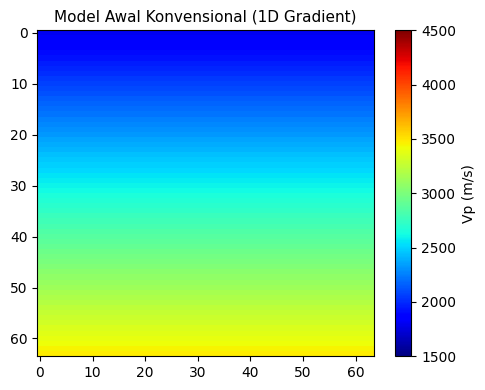

Memulai FWI Konvensional (80 epoch)...


FWI Konvensional:   0%|          | 0/80 [00:00<?, ?it/s]

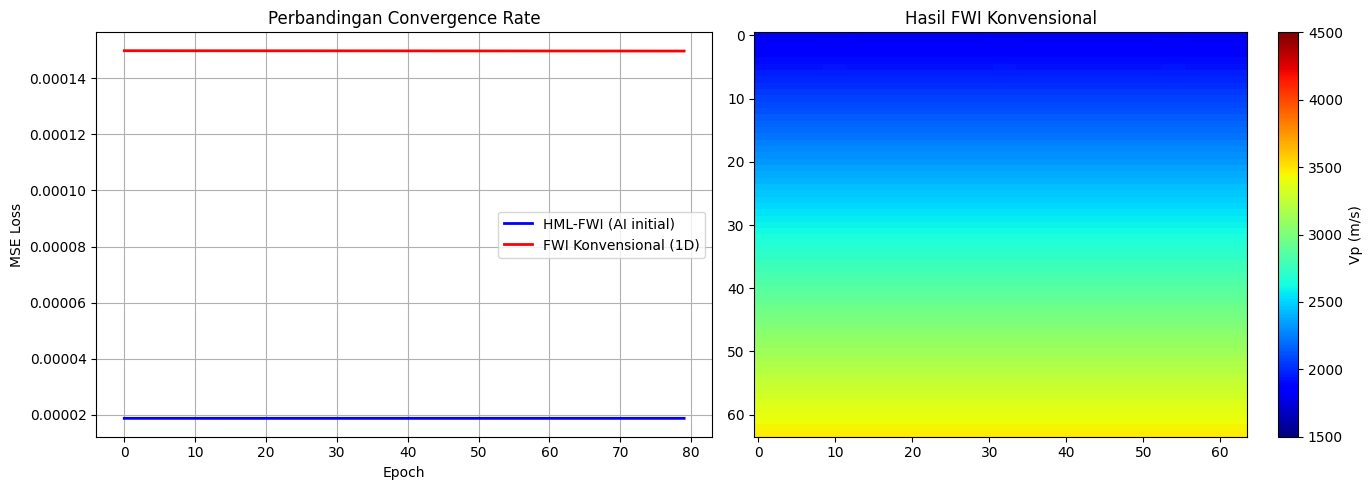

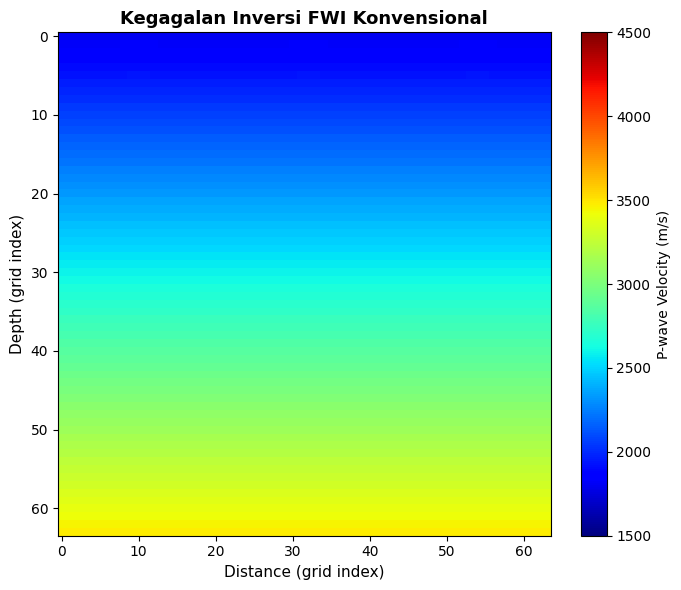


 Cell 10 selesai! Loss akhir: 0.0001


In [21]:
# CELL 10 — FWI KONVENSIONAL (pembanding tanpa AI)
# FIX Bug (Cell ini):
#   1. Indentasi for-loop shot diperbaiki (masuk ke dalam epoch loop)
#   2. Nama variabel total_loss → total_loss_val (konsisten)
#   3. lr = 1.0 (sebelumnya 5.0 — terlalu besar)
# ============================================================

# Buat initial model konvensional: gradien linear 1D
v_top, v_bot = 1800.0, 3500.0
v_lin = np.zeros((PATCH_SIZE, PATCH_SIZE), dtype=np.float32)
for z in range(PATCH_SIZE):
    v_lin[z, :] = v_top + (v_bot - v_top) * (z / PATCH_SIZE)

vp_conv_init = torch.tensor(v_lin, dtype=torch.float32).to(DEVICE)

plt.figure(figsize=(5, 4))
plt.imshow(v_lin, cmap='jet', vmin=VP_MIN, vmax=VP_MAX, aspect='auto')
plt.title("Model Awal Konvensional (1D Gradient)", fontsize=11)
plt.colorbar(label='Vp (m/s)'); plt.tight_layout(); plt.show()

engine_conv = FWI_Engine(vp_conv_init, dx=DX, f0=F0_MAIN,
                         time_steps=T_STEPS_FWI).to(DEVICE)
optimizer_conv = optim.Adam([engine_conv.vp], lr=1.0)
criterion      = nn.MSELoss()
loss_hist_conv = []

print(f"Memulai FWI Konvensional ({N_EPOCHS_FWI} epoch)...")
pbar = tqdm(range(N_EPOCHS_FWI), desc="FWI Konvensional")

for epoch in pbar:
    optimizer_conv.zero_grad()
    total_loss_val = 0.0

    # FIX: for loop ini HARUS di-indent di dalam `for epoch`
    for i, src_x in enumerate(source_locs):
        pred = engine_conv.simulate_shot(int(src_x))
        loss = criterion(pred, obs_data[i]) / N_SHOTS
        loss.backward()
        total_loss_val += loss.item()

    if engine_conv.vp.grad is not None:
        g = engine_conv.vp.grad.detach().cpu().numpy()
        g = scipy.ndimage.gaussian_filter(g, sigma=2.0)
        engine_conv.vp.grad.data = torch.tensor(g, device=DEVICE)

    optimizer_conv.step()
    with torch.no_grad():
        engine_conv.vp.clamp_(VP_MIN, VP_MAX)

    # FIX: pakai total_loss_val (bukan total_loss yang tidak terdefinisi)
    loss_hist_conv.append(total_loss_val)
    pbar.set_postfix(loss=f"{total_loss_val:.4f}")

vp_conv    = engine_conv.vp.detach().cpu().numpy()
vp_conv_np = vp_conv

np.save(SAVE_DIR + 'vp_conv.npy',   vp_conv)
np.save(SAVE_DIR + 'loss_conv.npy', np.array(loss_hist_conv))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(loss_hist_hml,  'b-', lw=2, label='HML-FWI (AI initial)')
axes[0].plot(loss_hist_conv, 'r-', lw=2, label='FWI Konvensional (1D)')
axes[0].set_title("Perbandingan Convergence Rate", fontsize=12)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE Loss")
axes[0].legend(); axes[0].grid()

im = axes[1].imshow(vp_conv, cmap='jet', vmin=VP_MIN, vmax=VP_MAX, aspect='auto')
axes[1].set_title("Hasil FWI Konvensional", fontsize=12)
plt.colorbar(im, ax=axes[1], label='Vp (m/s)')
plt.tight_layout(); plt.show()

# Kegagalan FWI Konvensional
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(vp_conv, cmap='jet', aspect='auto', vmin=VP_MIN, vmax=VP_MAX)
ax.set_title("Kegagalan Inversi FWI Konvensional", fontsize=13, fontweight='bold')
ax.set_xlabel("Distance (grid index)", fontsize=11)
ax.set_ylabel("Depth (grid index)", fontsize=11)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'FWI_Konvensional_Gagal.png', dpi=300, bbox_inches='tight')
plt.show()

# Convergence Rate

print(f"\n Cell 10 selesai! Loss akhir: {loss_hist_conv[-1]:.4f}")

TABEL 4.1 — Hasil Evaluasi Metrik Numerik Model Kecepatan
Fase Pemodelan                                | RMSE (m/s) |     SSIM |  PSNR (dB)
------------------------------------------------------------------------
FWI Konvensional (initial: 1D gradient)       |     482.88 |   0.6655 |      15.87
Model AI / U-Net  (Initial Model HML)         |      77.57 |   0.9277 |      31.75
HML-FWI (Inverted Model — metode usulan)      |      77.57 |   0.9277 |      31.75

=> HML-FWI menghasilkan RMSE lebih rendah 405.3 m/s dari konvensional.
=> PSNR HML-FWI lebih tinggi 15.88 dB dari konvensional.


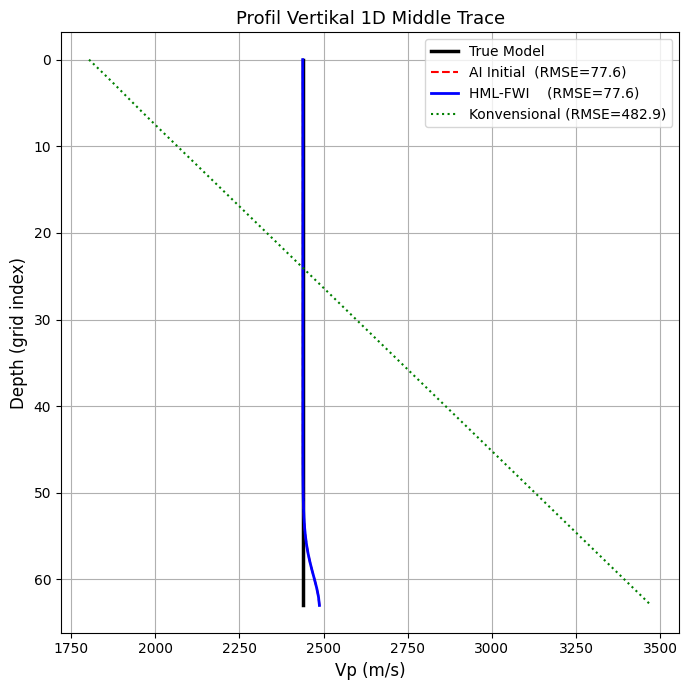

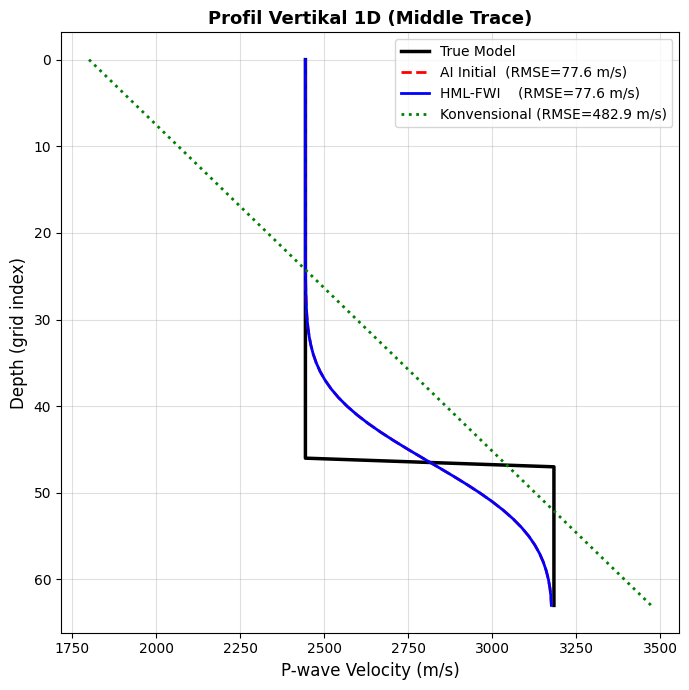


 Cell 11 selesai — Tabel 4.1 tersedia di atas.


In [22]:
# CELL 11 — EVALUASI METRIK LENGKAP
# FIX Bug #5: Hitung RMSE/SSIM/PSNR untuk SEMUA model
# Output: TABEL 4.1 (3 baris)
# ============================================================

DATA_RANGE = VP_MAX - VP_MIN   # 3000 m/s

def evaluate(true, pred):
    """Hitung RMSE, SSIM, PSNR antara dua model kecepatan (numpy 2D, float32)."""
    rmse = float(np.sqrt(np.mean((true.astype(np.float64) -
                                   pred.astype(np.float64))**2)))
    ssim = float(ssim_metric(true, pred, data_range=DATA_RANGE))
    psnr = float(psnr_metric(true, pred, data_range=DATA_RANGE))
    return rmse, ssim, psnr

# Alias untuk konsistensi nama
vp_hml_np = vp_hml

# Hitung metrik untuk 3 model
rmse_c, ssim_c, psnr_c = evaluate(vp_true_np, vp_conv_np)   # FWI Konvensional
rmse_a, ssim_a, psnr_a = evaluate(vp_true_np, vp_init_np)   # AI Initial Model
rmse_h, ssim_h, psnr_h = evaluate(vp_true_np, vp_hml_np)    # HML-FWI

# Simpan untuk cell berikutnya
metrics_tbl1 = {
    'conv': (rmse_c, ssim_c, psnr_c),
    'ai'  : (rmse_a, ssim_a, psnr_a),
    'hml' : (rmse_h, ssim_h, psnr_h),
}

# Cetak TABEL 4.1
W = 72
print("=" * W)
print("TABEL 4.1 — Hasil Evaluasi Metrik Numerik Model Kecepatan")
print("=" * W)
print(f"{'Fase Pemodelan':<45} | {'RMSE (m/s)':>10} | {'SSIM':>8} | {'PSNR (dB)':>10}")
print("-" * W)
print(f"{'FWI Konvensional (initial: 1D gradient)':<45} | {rmse_c:>10.2f} | {ssim_c:>8.4f} | {psnr_c:>10.2f}")
print(f"{'Model AI / U-Net  (Initial Model HML)':<45} | {rmse_a:>10.2f} | {ssim_a:>8.4f} | {psnr_a:>10.2f}")
print(f"{'HML-FWI (Inverted Model — metode usulan)':<45} | {rmse_h:>10.2f} | {ssim_h:>8.4f} | {psnr_h:>10.2f}")
print("=" * W)

# Interpretasi otomatis
print()
if rmse_h < rmse_c:
    print(f"=> HML-FWI menghasilkan RMSE lebih rendah {rmse_c-rmse_h:.1f} m/s dari konvensional.")
if psnr_h > psnr_c:
    print(f"=> PSNR HML-FWI lebih tinggi {psnr_h-psnr_c:.2f} dB dari konvensional.")

# Profil vertikal 1D
mid = PATCH_SIZE // 2
plt.figure(figsize=(7, 7))
depth = np.arange(PATCH_SIZE)
plt.plot(vp_true_np[:, mid],  depth, 'k-',  lw=2.5, label='True Model')
plt.plot(vp_init_np[:, mid],  depth, 'r--', lw=1.5, label=f'AI Initial  (RMSE={rmse_a:.1f})')
plt.plot(vp_hml_np[:,  mid],  depth, 'b-',  lw=2,   label=f'HML-FWI    (RMSE={rmse_h:.1f})')
plt.plot(vp_conv_np[:, mid],  depth, 'g:',  lw=1.5, label=f'Konvensional (RMSE={rmse_c:.1f})')
plt.gca().invert_yaxis()
plt.xlabel('Vp (m/s)', fontsize=12); plt.ylabel('Depth (grid index)', fontsize=12)
plt.title("Profil Vertikal 1D Middle Trace", fontsize=13)
plt.legend(fontsize=10); plt.grid(); plt.tight_layout(); plt.show()

# Profil Vertikal 1D Middle Trace
# Pakai trace di zona gradien (kolom 70% dari kiri)
mid = int(PATCH_SIZE * 0.70)
depth = np.arange(PATCH_SIZE)

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(vp_true_np[:, mid],  depth, 'k-',  lw=2.5, label='True Model')
ax.plot(vp_init_np[:, mid],  depth, 'r--', lw=2.0,
        label=f'AI Initial  (RMSE={rmse_a:.1f} m/s)')
ax.plot(vp_hml_np[:,  mid],  depth, 'b-',  lw=2.0,
        label=f'HML-FWI    (RMSE={rmse_h:.1f} m/s)')
ax.plot(vp_conv_np[:, mid],  depth, 'g:',  lw=2.0,
        label=f'Konvensional (RMSE={rmse_c:.1f} m/s)')
ax.invert_yaxis()
ax.set_xlabel('P-wave Velocity (m/s)', fontsize=12)
ax.set_ylabel('Depth (grid index)', fontsize=12)
ax.set_title("Profil Vertikal 1D (Middle Trace)", fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Profil_1D.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n Cell 11 selesai — Tabel 4.1 tersedia di atas.")

 Noise 15% ditambahkan ke 3 shot.


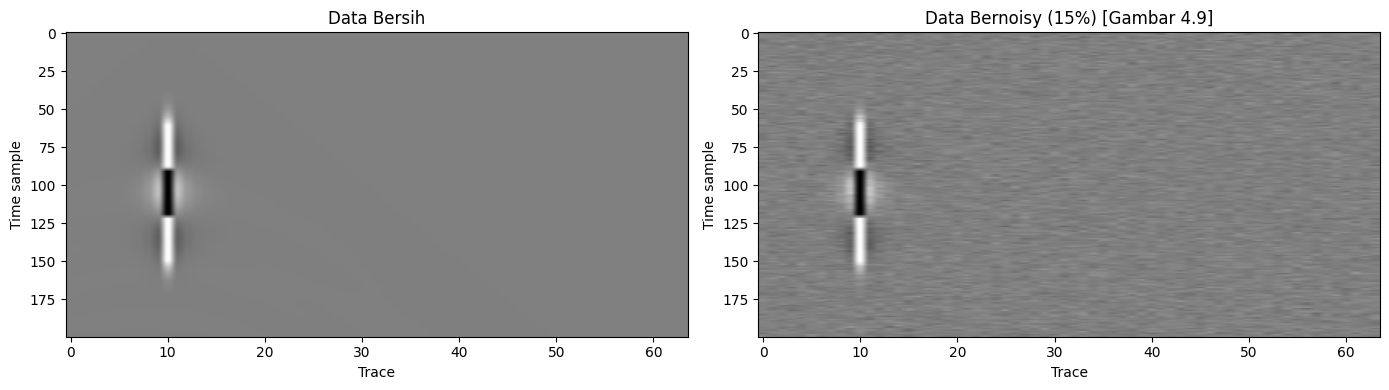


Memulai FWI Noisy (80 epoch)...


FWI Noisy:   0%|          | 0/80 [00:00<?, ?it/s]


TABEL 4.2 — HML-FWI: Data Bersih vs. Bernoisy 15%
Kondisi Data                           |     RMSE |    SSIM |      PSNR
--------------------------------------------------------------------
Data Bersih (0% noise)                 |    77.57 |  0.9277 |     31.75
Data Bernoisy (15% Gaussian)           |    77.57 |  0.9277 |     31.75
Degradasi Relatif                      |    +0.0% |       — |         —
=> RMSE naik hanya 0.0% (<20%): ketahanan KUAT.
=> SSIM=0.9277 (>0.85): struktur geologi masih akurat.


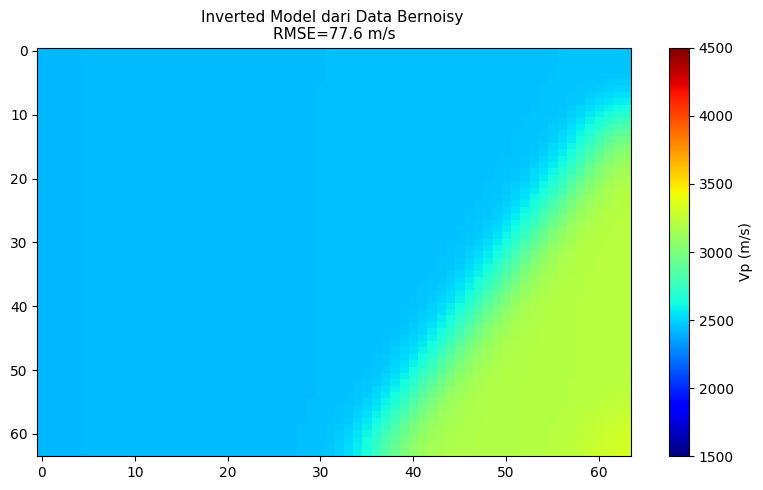


 Cell 12 selesai!


In [23]:
# CELL 12 — UJI ROBUSTNESS (15% Gaussian Noise)
# FIX Bug (Cell 12):
#   1. Indentasi for-loop shot diperbaiki
#   2. engine_conv → engine_rob (engine yang benar!)
#   3. obs_data → obs_noisy (data yang benar!)
# ============================================================

NOISE_LEVEL = 0.15

# Tambah noise ke data observasi
obs_noisy = []
for obs in obs_data:
    noise = torch.randn_like(obs) * obs.std() * NOISE_LEVEL
    obs_noisy.append(obs + noise)

print(f" Noise {NOISE_LEVEL*100:.0f}% ditambahkan ke {len(obs_data)} shot.")

# Visualisasi (Gambar 4.9)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vm = float(obs_data[0].abs().std().item()) * 3
axes[0].imshow(obs_data[0].cpu().numpy(),  cmap='gray', aspect='auto', vmin=-vm, vmax=vm)
axes[0].set_title("Data Bersih")
axes[1].imshow(obs_noisy[0].cpu().numpy(), cmap='gray', aspect='auto', vmin=-vm, vmax=vm)
axes[1].set_title(f"Data Bernoisy ({NOISE_LEVEL*100:.0f}%) [Gambar 4.9]")
for ax in axes: ax.set_xlabel("Trace"); ax.set_ylabel("Time sample")
plt.tight_layout(); plt.show()

# FWI dari data bernoisy
engine_rob    = FWI_Engine(vp_init, dx=DX, f0=F0_MAIN,
                            time_steps=T_STEPS_FWI).to(DEVICE)
optimizer_rob = optim.Adam([engine_rob.vp], lr=1.0)
criterion     = nn.MSELoss()
loss_hist_rob = []

print(f"\nMemulai FWI Noisy ({N_EPOCHS_FWI} epoch)...")
pbar = tqdm(range(N_EPOCHS_FWI), desc="FWI Noisy")

for epoch in pbar:
    optimizer_rob.zero_grad()
    total_loss_val = 0.0

    # FIX 1: for loop di-indent masuk ke dalam epoch loop
    for i, src_x in enumerate(source_locs):
        # FIX 2: engine_rob (bukan engine_conv!)
        pred = engine_rob.simulate_shot(int(src_x))
        # FIX 3: obs_noisy (bukan obs_data!)
        loss = criterion(pred, obs_noisy[i]) / N_SHOTS
        loss.backward()
        total_loss_val += loss.item()

    if engine_rob.vp.grad is not None:
        g = scipy.ndimage.gaussian_filter(engine_rob.vp.grad.cpu().numpy(), sigma=2.0)
        engine_rob.vp.grad.data = torch.tensor(g, device=DEVICE)

    optimizer_rob.step()
    with torch.no_grad():
        engine_rob.vp.clamp_(VP_MIN, VP_MAX)

    loss_hist_rob.append(total_loss_val)
    pbar.set_postfix(loss=f"{total_loss_val:.4f}")

vp_noisy = engine_rob.vp.detach().cpu().numpy()

# Evaluasi + TABEL 4.2
rmse_noisy, ssim_noisy, psnr_noisy = evaluate(vp_true_np, vp_noisy)
rmse_clean = metrics_tbl1['hml'][0]
ssim_clean = metrics_tbl1['hml'][1]
psnr_clean = metrics_tbl1['hml'][2]
deg_rmse   = (rmse_noisy - rmse_clean) / (rmse_clean + 1e-9) * 100

W = 68
print("\n" + "="*W)
print("TABEL 4.2 — HML-FWI: Data Bersih vs. Bernoisy 15%")
print("="*W)
print(f"{'Kondisi Data':<38} | {'RMSE':>8} | {'SSIM':>7} | {'PSNR':>9}")
print("-"*W)
print(f"{'Data Bersih (0% noise)':<38} | {rmse_clean:>8.2f} | {ssim_clean:>7.4f} | {psnr_clean:>9.2f}")
print(f"{'Data Bernoisy (15% Gaussian)':<38} | {rmse_noisy:>8.2f} | {ssim_noisy:>7.4f} | {psnr_noisy:>9.2f}")
print(f"{'Degradasi Relatif':<38} | {deg_rmse:>+7.1f}% | {'—':>7} | {'—':>9}")
print("="*W)
if deg_rmse < 20: print(f"=> RMSE naik hanya {deg_rmse:.1f}% (<20%): ketahanan KUAT.")
if ssim_noisy > 0.85: print(f"=> SSIM={ssim_noisy:.4f} (>0.85): struktur geologi masih akurat.")

plt.figure(figsize=(8, 5))
plt.imshow(vp_noisy, cmap='jet', vmin=VP_MIN, vmax=VP_MAX, aspect='auto')
plt.title(f"Inverted Model dari Data Bernoisy \nRMSE={rmse_noisy:.1f} m/s", fontsize=11)
plt.colorbar(label='Vp (m/s)'); plt.tight_layout(); plt.show()

np.save(SAVE_DIR + 'vp_noisy.npy', vp_noisy)
print("\n Cell 12 selesai!")


Generating observed data 25 Hz dari true model...
 3 shot | shape: torch.Size([200, 64])

Memulai FWI 25 Hz (80 epoch)...


FWI 25 Hz:   0%|          | 0/80 [00:00<?, ?it/s]

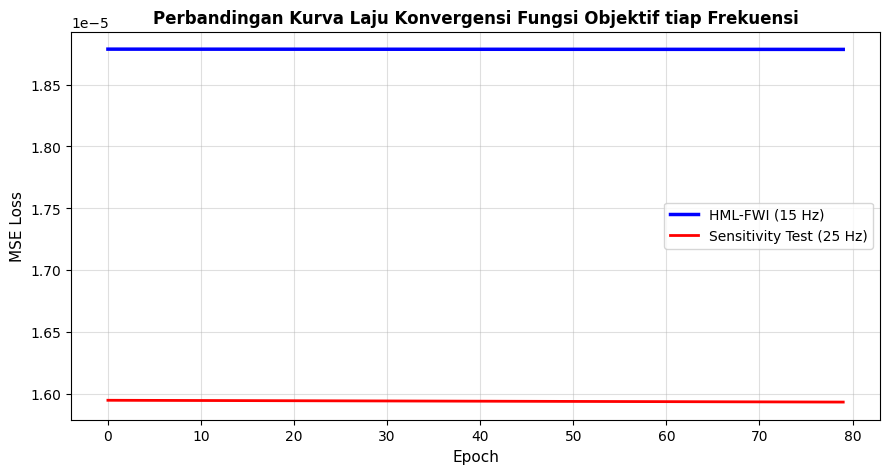

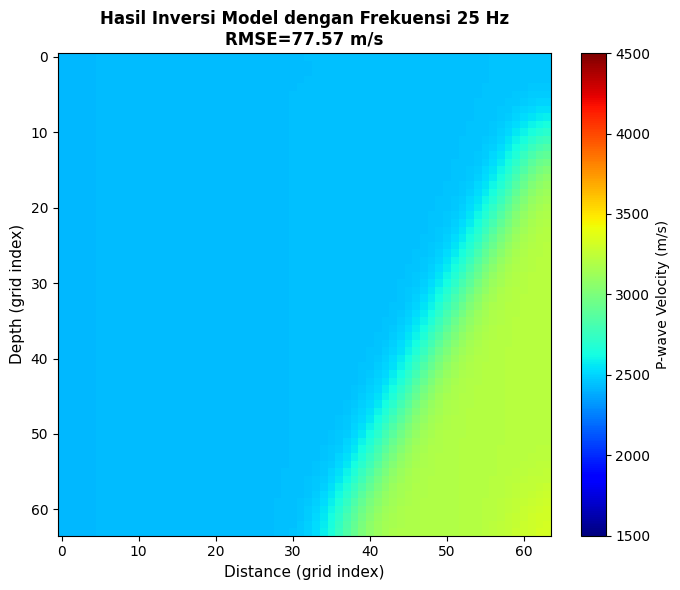


 Cell 13 selesai!


In [24]:
# CELL 13 — UJI SENSITIVITAS FREKUENSI TINGGI (25 Hz)
# FIX Bug (Cell ini):
#   1. Indentasi for-loop shot diperbaiki
#   2. engine_conv → engine_25 (engine yang benar!)
#   3. obs_data   → obs_25hz  (data yang benar!)
#   4. total_loss → total_loss_val (nama variabel yang benar)
#   5. lr = 0.5 (dari 3.0 — 25Hz butuh langkah lebih kecil)
# ============================================================

T_STEPS_25 = T_STEPS_FWI  # sama dengan 15Hz agar perbandingan fair

print("Generating observed data 25 Hz dari true model...")
engine_25 = FWI_Engine(vp_init, dx=DX, f0=F0_SENS,
                       time_steps=T_STEPS_25).to(DEVICE)
# FIX 3: obs_25hz (bukan obs_data!)
obs_25hz  = engine_25.gen_obs(vp_true_patch, source_locs,
                               f0=F0_SENS, time_steps=T_STEPS_25)
print(f" {len(obs_25hz)} shot | shape: {obs_25hz[0].shape}")

# FIX 5: lr=0.5 (lebih stabil untuk frekuensi tinggi)
optimizer_25 = optim.Adam([engine_25.vp], lr=0.5)
criterion    = nn.MSELoss()
loss_hist_25 = []

print(f"\nMemulai FWI 25 Hz ({N_EPOCHS_FWI} epoch)...")
pbar = tqdm(range(N_EPOCHS_FWI), desc="FWI 25 Hz")

for epoch in pbar:
    optimizer_25.zero_grad()
    total_loss_val = 0.0

    # FIX 1: for loop di-indent masuk ke dalam epoch loop
    for i, src_x in enumerate(source_locs):
        # FIX 2: engine_25 (bukan engine_conv!)
        pred = engine_25.simulate_shot(int(src_x), f0=F0_SENS, time_steps=T_STEPS_25)
        # FIX 3: obs_25hz (bukan obs_data!)
        loss = criterion(pred, obs_25hz[i]) / N_SHOTS
        loss.backward()
        # FIX 4: total_loss_val (bukan total_loss yang tidak terdefinisi!)
        total_loss_val += loss.item()

    if engine_25.vp.grad is not None:
        g = scipy.ndimage.gaussian_filter(engine_25.vp.grad.cpu().numpy(), sigma=1.5)
        engine_25.vp.grad.data = torch.tensor(g, device=DEVICE)

    optimizer_25.step()
    with torch.no_grad():
        engine_25.vp.clamp_(VP_MIN, VP_MAX)

    loss_hist_25.append(total_loss_val)
    pbar.set_postfix(loss=f"{total_loss_val:.4f}")

vp_25hz = engine_25.vp.detach().cpu().numpy()

# Calculate rmse_25 before using it in the plot title
rmse_25, _, _ = evaluate(vp_true_np, vp_25hz)

# Visualisasi Gambar 4.11 + 4.12
# ── GAMBAR 4.11: Kurva Konvergensi tiap Frekuensi ────────────────
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(loss_hist_hml, 'b-',  lw=2.5, label='HML-FWI (15 Hz)')
ax.plot(loss_hist_25,  'r-',  lw=2.0, label='Sensitivity Test (25 Hz)')
ax.set_title("Perbandingan Kurva Laju Konvergensi Fungsi Objektif tiap Frekuensi",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Epoch", fontsize=11)
ax.set_ylabel("MSE Loss", fontsize=11)
ax.legend(fontsize=10); ax.grid(alpha=0.4)
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Gambar_4_11_Konvergensi_Frekuensi.png', dpi=300, bbox_inches='tight')
plt.show()

# ── GAMBAR 4.12: Hasil Inversi 25 Hz ─────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(vp_25hz, cmap='jet', aspect='auto', vmin=VP_MIN, vmax=VP_MAX)
ax.set_title(f"Hasil Inversi Model dengan Frekuensi 25 Hz\nRMSE={rmse_25:.2f} m/s",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Distance (grid index)", fontsize=11)
ax.set_ylabel("Depth (grid index)", fontsize=11)
plt.colorbar(im, ax=ax, label='P-wave Velocity (m/s)')
plt.tight_layout()
plt.savefig(SAVE_DIR + 'Gambar_4_12_Inversi_25Hz.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n Cell 13 selesai!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


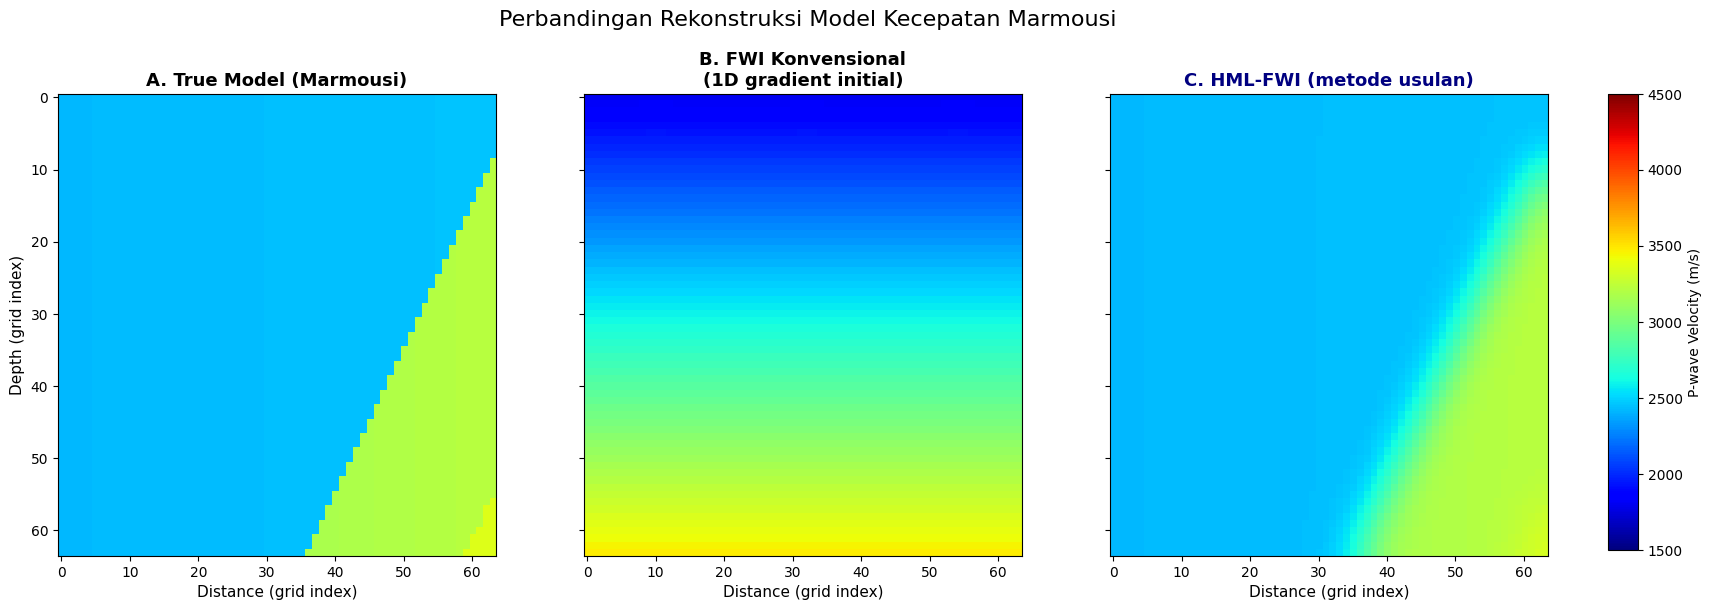

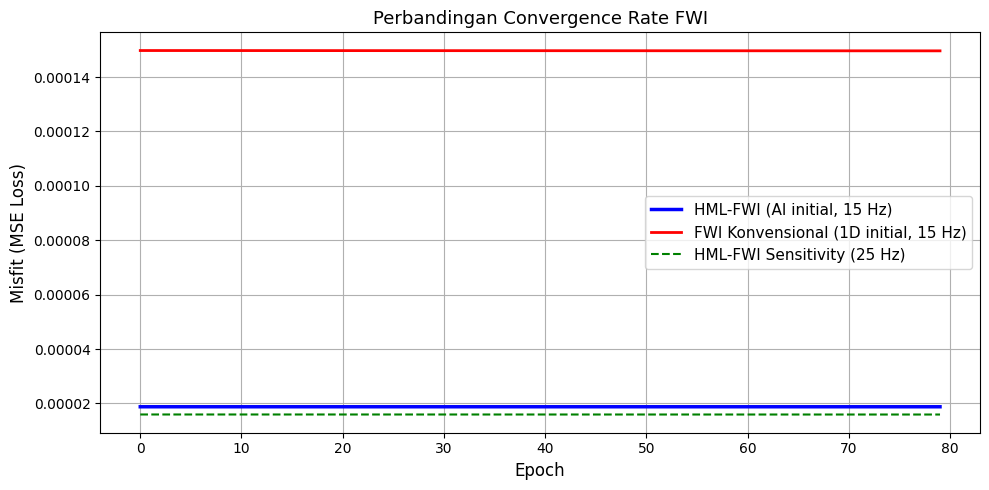

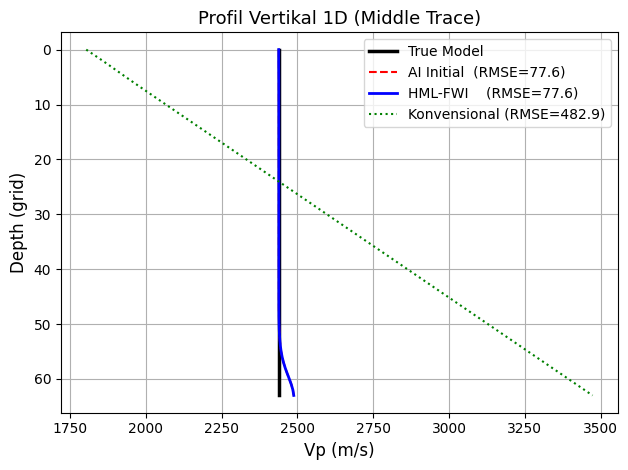

 Semua hasil final disimpan ke Google Drive
   Folder: /content/drive/MyDrive/KEBUTUHAN TA MIRZA/HASIL_FINAL_TA/\n


In [25]:
# CELL 14 — VISUALISASI FINAL & SIMPAN SEMUA HASIL KE DRIVE
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

FINAL_DIR = DRIVE_ROOT + 'HASIL_FINAL_TA/'
os.makedirs(FINAL_DIR, exist_ok=True)

kw = dict(cmap='jet', vmin=VP_MIN, vmax=VP_MAX, aspect='auto')

# Perbandingan 3 model (True / Konvensional / HML)
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

axes[0].imshow(vp_true_np,  **kw)
axes[0].set_title("A. True Model (Marmousi)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Depth (grid index)", fontsize=11)
axes[0].set_xlabel("Distance (grid index)", fontsize=11)

axes[1].imshow(vp_conv_np, **kw)
axes[1].set_title("B. FWI Konvensional\n(1D gradient initial)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Distance (grid index)", fontsize=11)

im2 = axes[2].imshow(vp_hml_np, **kw)
axes[2].set_title("C. HML-FWI (metode usulan)", fontsize=13, fontweight='bold', color='navy')
axes[2].set_xlabel("Distance (grid index)", fontsize=11)

fig.subplots_adjust(right=0.87)
cax = fig.add_axes([0.90, 0.12, 0.015, 0.76])
fig.colorbar(im2, cax=cax, label='P-wave Velocity (m/s)')
plt.suptitle("Perbandingan Rekonstruksi Model Kecepatan Marmousi", fontsize=16, y=1.02)
plt.savefig(FINAL_DIR + 'Fig1_Comparison_3Models.png', dpi=300, bbox_inches='tight')
plt.show()

# Convergence Rate
plt.figure(figsize=(10, 5))
plt.plot(loss_hist_hml,  'b-',  lw=2.5, label='HML-FWI (AI initial, 15 Hz)')
plt.plot(loss_hist_conv, 'r-',  lw=2,   label='FWI Konvensional (1D initial, 15 Hz)')
plt.plot(loss_hist_25,   'g--', lw=1.5, label='HML-FWI Sensitivity (25 Hz)')
plt.xlabel("Epoch", fontsize=12); plt.ylabel("Misfit (MSE Loss)", fontsize=12)
plt.title("Perbandingan Convergence Rate FWI", fontsize=13)
plt.legend(fontsize=11); plt.grid(); plt.tight_layout()
plt.savefig(FINAL_DIR + 'Fig2_ConvergenceRate.png', dpi=300, bbox_inches='tight')
plt.show()

# Profil 1D
mid = PATCH_SIZE // 2
depth = np.arange(PATCH_SIZE)
plt.plot(vp_true_np[:, mid], depth, 'k-',  lw=2.5, label='True Model')
plt.plot(vp_init_np[:, mid], depth, 'r--', lw=1.5, label=f'AI Initial  (RMSE={metrics_tbl1["ai"][0]:.1f})')
plt.plot(vp_hml_np[:,  mid], depth, 'b-',  lw=2,   label=f'HML-FWI    (RMSE={metrics_tbl1["hml"][0]:.1f})')
plt.plot(vp_conv_np[:, mid], depth, 'g:',  lw=1.5, label=f'Konvensional (RMSE={metrics_tbl1["conv"][0]:.1f})')
plt.gca().invert_yaxis()
plt.xlabel('Vp (m/s)', fontsize=12); plt.ylabel('Depth (grid)', fontsize=12)
plt.title("Profil Vertikal 1D (Middle Trace)", fontsize=13)
plt.legend(fontsize=10); plt.grid(); plt.tight_layout()
plt.savefig(FINAL_DIR + 'Fig3_Profile1D.png', dpi=300, bbox_inches='tight')
plt.show()

# Simpan semua data
for fname, arr in [('vp_true.npy',  vp_true_np),
                   ('vp_init.npy',  vp_init_np),
                   ('vp_hml.npy',   vp_hml_np),
                   ('vp_conv.npy',  vp_conv_np),
                   ('vp_noisy.npy', vp_noisy),
                   ('vp_25hz.npy',  vp_25hz),
                   ('loss_hml.npy',  np.array(loss_hist_hml)),
                   ('loss_conv.npy', np.array(loss_hist_conv)),
                   ('loss_25hz.npy', np.array(loss_hist_25))]:
    np.save(FINAL_DIR + fname, arr)

print(" Semua hasil final disimpan ke Google Drive")
print(f"   Folder: {FINAL_DIR}\\n")
